# Bandaged cube difficulty study

100 random bandaged 3x3x3 cubes, measured with the same KPIs as the plain cube (the baseline).
The data comes from

```bash
cargo run --release --bin bandage_study -- --n 100 --seed 2026 --alg-time 10 --out study
```

which writes `study/results.json` (this notebook) and `study/results.csv`. All moves are the
18 face turns (HTM: a quarter or half turn of one face counts as one move).

## Bandage notation

A **cubie** is named by the faces it touches, from the 6 face letters
`U` (up), `D` (down), `R` (right), `L` (left), `F` (front), `B` (back):

| piece | names | count |
|---|---|---|
| corner | `URF UFL ULB UBR DFR DLF DBL DRB` | 8 |
| edge | `UR UF UL UB DR DF DL DB FR FL BL BR` | 12 |
| center | `U R F D L B` | 6 |

Letter order does not matter (`FU` = `UF`, `RFU` = `URF`).

A **block** is a group of cubies glued together, written with `+`: `URF+UF` glues the URF corner to
the UF edge, a 1x1x2 block. Blocks are separated by `|` (or `,`/`;`): `URF+UF | DF+D` has two
blocks. Gluing an edge to a center (`DF+D`) makes that center part of the block.

A turn is **legal** only if it does not cut a block, i.e. every block is either completely inside or
completely outside the turning layer. In `URF+UF`, `U` is legal (both cubies are in the U layer), `R`
is not (URF is in R, UF is not). Blocks travel with their cubies, so after some turns other faces
become blocked: the puzzle changes *shape*.

The random generator glues 1 to 12 random pairs of touching cubies (corner-edge or edge-center; 48
possible pairs). Pairs that share a cubie merge into bigger blocks, e.g. `URF+UF+U+UR` is a 2x2x1
block containing the U center, which means the U face can never turn on its own.

In the drawings below, glued stickers are joined by a bridge of their color.

URF+UF                       legal at start: L L2 L' U U2 U' D D2 D' F F2 F' B B2 B'
URF+UF | DF+D                legal at start: L L2 L' U U2 U' D D2 D' B B2 B'
UF+UFR+UR+U | DF+D           legal at start: L L2 L' U U2 U' D D2 D' B B2 B'
DLF+FL | DFR+DF+D | BL+L     legal at start: L L2 L' U U2 U'


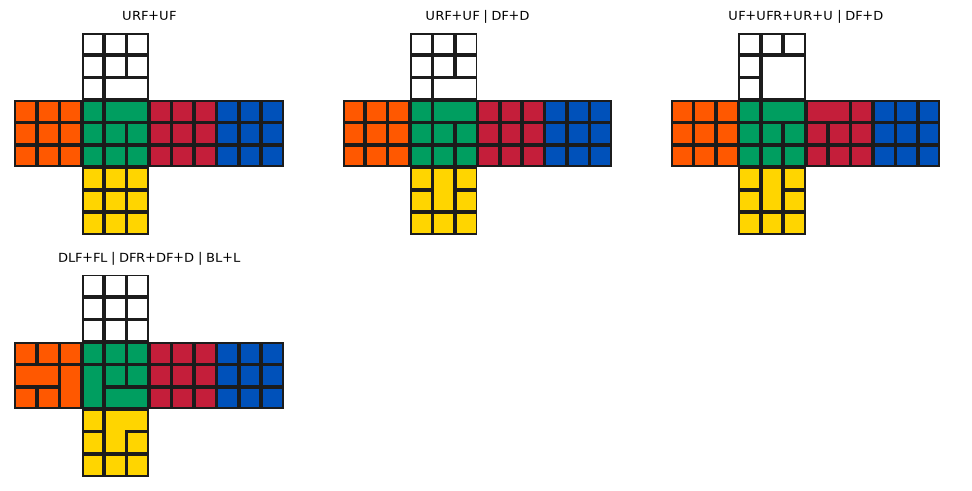

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rubik

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

examples = ["URF+UF", "URF+UF | DF+D", "UF+UFR+UR+U | DF+D", "DLF+FL | DFR+DF+D | BL+L"]
rubik.plot_cubes([rubik.Cube(bandage=b) for b in examples], titles=examples)
for b in examples:
    print(f"{b:28s} legal at start: {' '.join(rubik.Cube(bandage=b).legal_moves('htm'))}")

## The data

One row per puzzle; `333` is the baseline. Key columns:

* `states`: reachable positions, **exact for every puzzle** (shapes × order of the group of shape-preserving loops, Schreier-Sims).
* `gods_number`: worst-case optimal solution, exact when the puzzle is small enough to enumerate (`complete`). Otherwise `gods_lower` is a proven lower bound and `gods_counting` an estimate.
* `mean_distance`: optimal solution length of a random position. Exact if `mean_distance_exact`, otherwise a **lower bound** (some sampled positions were too deep to solve).
* `branching`: legal face turns in a random position (18 on the 3x3x3).
* `<kind>`: shortest algorithm for an edge 3-cycle, corner 3-cycle, 2-edge flip, 2-corner twist that leaves everything else (blocks included) solved; `<kind>_exact` says if it is proven optimal, `<kind>_possible` how many such effects exist at all.

In [2]:
KINDS = ["edge3", "corner3", "edge_flip", "corner_twist"]
raw = json.load(open("../study/results.json", encoding="utf-8"))
rows = []
for r in raw:
    row = {k: v for k, v in r.items() if k not in ("algs", "layer_sizes")}
    row["layer_sizes"] = r["layer_sizes"]
    for k in KINDS:
        a = r["algs"][k]
        row[k] = a["min_len"]
        row[k + "_exact"] = a["exact"]
        row[k + "_possible"] = a.get("possible")
        row[k + "_example"] = a["example"]
    rows.append(row)
df = pd.DataFrame(rows).set_index("id")
for col in ["gods_number", "gods_counting", "states"] + KINDS + [k + "_possible" for k in KINDS]:
    df[col] = pd.to_numeric(df[col])
df["log10_states"] = np.log10(df["states"].astype(float))
base = df.loc["333"]
bp = df.drop("333")
print(f"{len(bp)} bandaged puzzles, {bp.complete.sum()} small enough to enumerate completely")
df[["spec", "log10_states", "complete", "gods_number", "gods_lower", "mean_distance",
    "mean_distance_exact", "branching"] + KINDS].head(12)

73 bandaged puzzles, 11 small enough to enumerate completely


,spec,log10_states,complete,gods_number,gods_lower,mean_distance,mean_distance_exact,branching,edge3,corner3,edge_flip,corner_twist
id,,,,,,,,,,,,
333,,19.636006,False,20.0,20,17.7000,True,18.0000,6.0,8.0,13.0,12.0
B001,URF+UBR+UR | DFR+DF | UB+B,14.034851,False,NaN,19,18.0446,False,8.5982,7.0,NaN,13.0,13.0
B002,DR+R | UL+U+L | UB+B,16.788434,False,NaN,16,15.3304,False,8.6518,8.0,8.0,13.0,13.0
B003,ULB+UB | UR+U | UF+F | DR+D | DL+L,15.175516,False,NaN,20,18.5714,False,6.6964,12.0,9.0,14.0,14.0
B004,ULB+UBR+UB | DLF+DF | URF+FR | DR+R | UF+UL+U+F | DL+D | BR+B,5.884927,True,55.0,55,35.3199,True,4.1250,35.0,NaN,15.0,31.0
B005,UBR+UR | UFL+UF | DBL+DB | DR+D | ULB+BL+B,11.376273,False,NaN,24,20.4375,False,6.2411,12.0,11.0,14.0,16.0
B006,UBR+UB | FL+L,17.477644,False,NaN,13,13.0000,False,12.6964,6.0,8.0,13.0,12.0
B007,UL+U | DR+R | DLF+DF+F+D,12.948830,False,NaN,20,19.1071,False,6.2946,12.0,10.0,14.0,16.0
B008,UBR+UR | UFL+DLF+FL | FR+R | DB+D | DBL+BL+L,9.932465,False,NaN,29,23.6875,True,5.4911,6.0,NaN,15.0,21.0


## Summary against the 3x3x3

In [3]:
def share(mask):
    return f"{mask.sum()} / {len(mask)} ({mask.mean():.0%})"

longer = bp.mean_distance > base.mean_distance            # lower bounds above 17.7 are proofs
shorter = bp.mean_distance_exact & (bp.mean_distance < base.mean_distance)
summary = pd.Series({
    "fewer states than 3x3x3": share(bp.log10_states < base.log10_states),
    "median log10 states (3x3x3: %.2f)" % base.log10_states: f"{bp.log10_states.median():.2f}",
    "mean solution provably LONGER than 3x3x3": share(longer),
    "mean solution provably SHORTER than 3x3x3": share(shorter),
    "undecided (lower bound below 17.7)": share(~longer & ~shorter),
    "largest exact God's number (3x3x3: 20)": int(bp.gods_number.max()),
    "median legal turns (3x3x3: 18)": f"{bp.branching.median():.1f}",
})
summary.to_frame("value")

,value
fewer states than 3x3x3,73 / 73 (100%)
median log10 states (3x3x3: 19.64),14.03
mean solution provably LONGER than 3x3x3,28 / 73 (38%)
mean solution provably SHORTER than 3x3x3,5 / 73 (7%)
undecided (lower bound below 17.7),40 / 73 (55%)
largest exact God's number (3x3x3: 20),155
median legal turns (3x3x3: 18),7.6


## State space against solution length

The central result. Every bandaged cube has fewer positions than the 3x3x3, often by many orders
of magnitude, yet many need **more** moves to solve. A bandage removes positions, but it also removes
moves, and the remaining paths through the puzzle are long and narrow.

Hollow markers are lower bounds (the true value is at or above the marker). The red dot and dashed
lines are the 3x3x3.

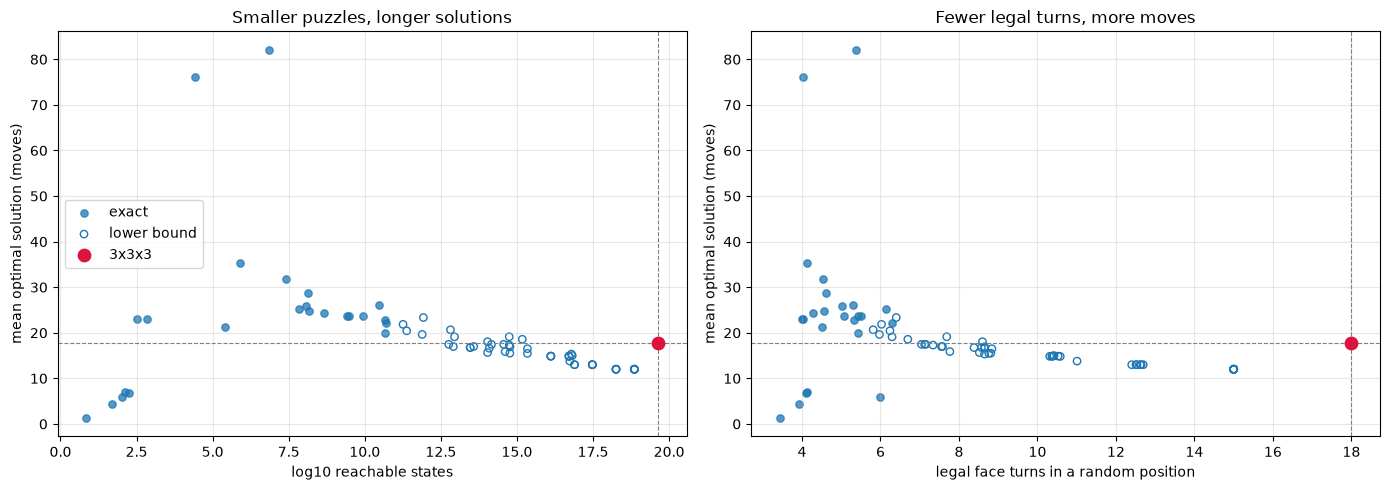

In [4]:
def scatter(ax, x, y, exact, xlabel, ylabel, bx, by):
    ax.scatter(x[exact], y[exact], s=28, c="C0", alpha=.75, label="exact")
    ax.scatter(x[~exact], y[~exact], s=28, facecolors="none", edgecolors="C0", label="lower bound")
    ax.scatter([bx], [by], s=80, c="crimson", zorder=5, label="3x3x3")
    ax.axvline(bx, ls="--", c="grey", lw=.8); ax.axhline(by, ls="--", c="grey", lw=.8)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(alpha=.3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ex = bp.mean_distance_exact.astype(bool)
scatter(axes[0], bp.log10_states, bp.mean_distance, ex, "log10 reachable states", "mean optimal solution (moves)",
        base.log10_states, base.mean_distance)
axes[0].set_title("Smaller puzzles, longer solutions")
scatter(axes[1], bp.branching, bp.mean_distance, ex, "legal face turns in a random position", "mean optimal solution (moves)",
        base.branching, base.mean_distance)
axes[1].set_title("Fewer legal turns, more moves")
axes[0].legend(); plt.tight_layout()

## God's number where it is exact

For puzzles small enough to enumerate, the exact worst case. Tiny puzzles can still need several
times the 3x3x3's 20 moves: their positions form long chains rather than a dense web.

,spec,states,gods_number,mean_distance,branching
id,,,,,
B018,UBR+UB | DBL+DB | FR+F | DLF+DR+DF+DL+D | UR+BR+R+B,27072.0,155.0,76.2072,4.0213
B053,ULB+UBR+UB | URF+DFR+FR | UFL+FL | BR+R | DF+F | DR+D | BL+L,7107840.0,124.0,82.0996,5.3647
B004,ULB+UBR+UB | DLF+DF | URF+FR | DR+R | UF+UL+U+F | DL+D | BR+B,767232.0,55.0,35.3199,4.1250
B026,DLF+DL | UFL+FL | DBL+BL | DFR+DRB+DR+BR | FR+F,324.0,45.0,23.0679,4.0000
B047,DFR+DF | UF+U+F | DBL+DL+DB+D | FL+BL+L | UB+BR+B,696.0,43.0,23.1149,4.0345
B065,URF+UR+UF | DFR+DR | DBL+DL | UFL+FL | UL+U,259200.0,30.0,21.2520,4.5000
B046,URF+UR+UF+UL+U | FR+FL+F | UBR+UB+DB+B,128.0,13.0,7.0391,4.1250
B059,ULB+DBL+DL+BL | UBR+BR | DR+R | DRB+DB+B,176.0,12.0,6.8977,4.0909


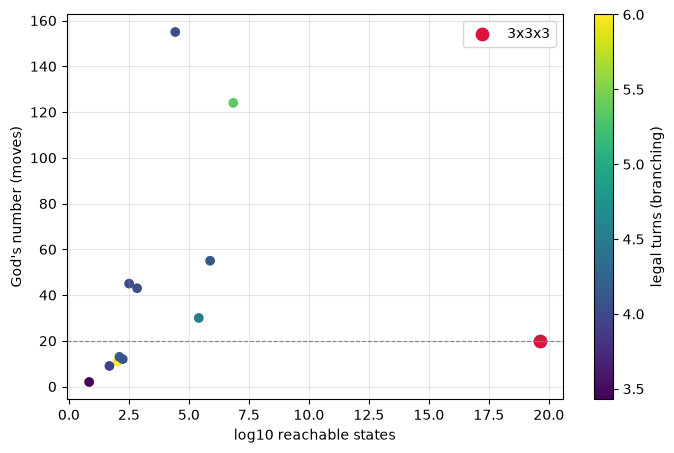

In [5]:
c = bp[bp.complete]
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(c.log10_states, c.gods_number, c=c.branching, cmap="viridis", s=36)
ax.scatter([base.log10_states], [base.gods_number], c="crimson", s=80, label="3x3x3")
ax.axhline(base.gods_number, ls="--", c="grey", lw=.8)
plt.colorbar(sc, label="legal turns (branching)")
ax.set_xlabel("log10 reachable states"); ax.set_ylabel("God's number (moves)"); ax.grid(alpha=.3); ax.legend()
c.sort_values("gods_number", ascending=False)[["spec", "states", "gods_number", "mean_distance", "branching"]].head(8)

### Distance distribution of the deepest complete puzzle

How many positions are at each distance from solved, against the start of the 3x3x3's curve. The
3x3x3 grows by about 13x per move; a heavily bandaged puzzle grows barely at all.

a farthest position: D2 F' D' L D F D' L2 D F' D' L D F D' L2 D F' D' L' D F D' L2 D F' D' L2 D F D' L2 D F' D' L D F D' L2 D F' D' L' D F D' L2 D F' D' L2 D F D' L2 D F' D' L D F D' L2 D F' D' L' D F D' L2 D F' D' L' D F D' L2 D F' D' L D F D' L2 D F' D' L' D F D' L2 D F' D' L2 D F D' L2 D F' D' L D F D' L2 D F' D' L' D F D' L2 D F' D' L2 D F D' L2 D F' D' L D F D' L2 D F' D' L' D F D' L D F' D' L D F D' L' D F2 D


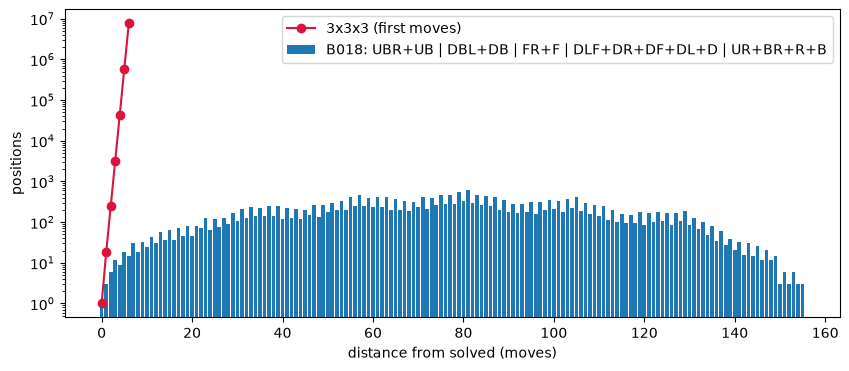

In [6]:
deep = c.gods_number.idxmax()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(c.loc[deep, "layer_sizes"])), c.loc[deep, "layer_sizes"], color="C0", label=f"{deep}: {c.loc[deep, 'spec']}")
ax.plot(range(len(base.layer_sizes)), base.layer_sizes, "o-", c="crimson", label="3x3x3 (first moves)")
ax.set_yscale("log"); ax.set_xlabel("distance from solved (moves)"); ax.set_ylabel("positions"); ax.legend()
print("a farthest position:", c.loc[deep, "antipode"])

## Algorithms: 3-cycles, flips and twists

The building blocks of a human solve. Each dot is the shortest algorithm on one puzzle (hollow: best
found, not proven optimal). The red tick is the 3x3x3. On the right, the share of puzzles where that
effect is possible at all; when it is not, a human cannot solve the free pieces with that technique.

,3x3x3,median bandaged,share longer than 3x3x3,not found / impossible
edge 3-cycle,6.0,7.0,55%,8
corner 3-cycle,8.0,8.0,30%,23
2-edge flip,13.0,13.0,48%,8
2-corner twist,12.0,13.0,69%,8


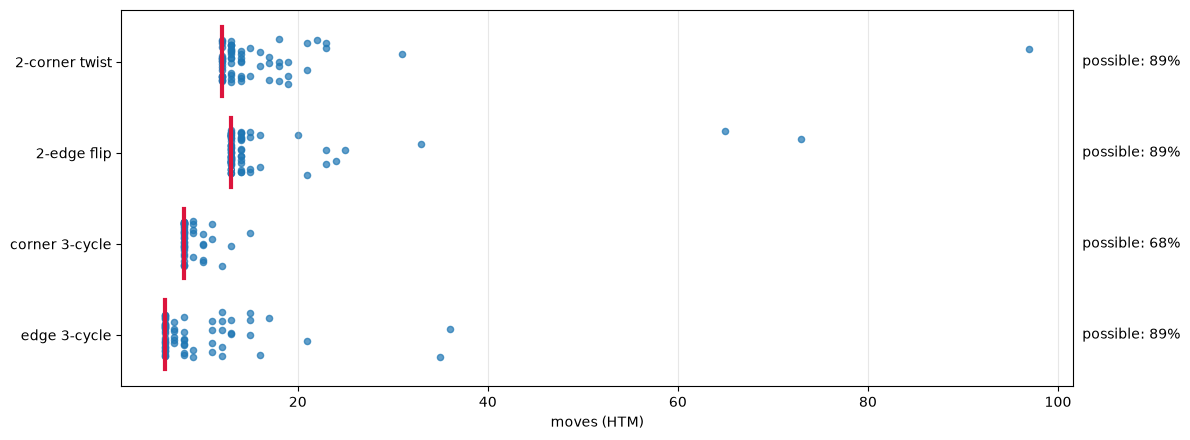

In [7]:
labels = {"edge3": "edge 3-cycle", "corner3": "corner 3-cycle", "edge_flip": "2-edge flip", "corner_twist": "2-corner twist"}
fig, ax = plt.subplots(figsize=(12, 4.5))
rng = np.random.default_rng(0)
for i, k in enumerate(KINDS):
    v = bp[bp[k].notna()]
    y = i + rng.uniform(-.25, .25, len(v))
    e = v[k + "_exact"].astype(bool).values
    ax.scatter(v[k][e], y[e], s=20, c="C0", alpha=.7)
    ax.scatter(v[k][~e], y[~e], s=20, facecolors="none", edgecolors="C0")
    if pd.notna(base[k]):
        ax.plot([base[k]] * 2, [i - .38, i + .38], c="crimson", lw=3)
    if bp[k + "_possible"].notna().all():
        ax.text(1.01, i, f"possible: {(bp[k + '_possible'] > 0).mean():.0%}", transform=ax.get_yaxis_transform(), va="center")
ax.set_yticks(range(4), [labels[k] for k in KINDS]); ax.set_xlabel("moves (HTM)"); ax.grid(axis="x", alpha=.3)
plt.tight_layout()

pd.DataFrame({
    "3x3x3": [base[k] for k in KINDS],
    "median bandaged": [bp[k].median() for k in KINDS],
    "share longer than 3x3x3": [f"{(bp[k] > base[k]).sum() / bp[k].notna().sum():.0%}" for k in KINDS],
    "not found / impossible": [int(bp[k].isna().sum()) for k in KINDS],
}, index=[labels[k] for k in KINDS])

## What makes a bandage hard?

How the KPIs move with the number of glued pairs. More glue shrinks the state space
steadily, but solution length peaks in the middle: lightly bandaged cubes behave like a 3x3x3, and
very heavily bandaged ones collapse to a handful of positions.

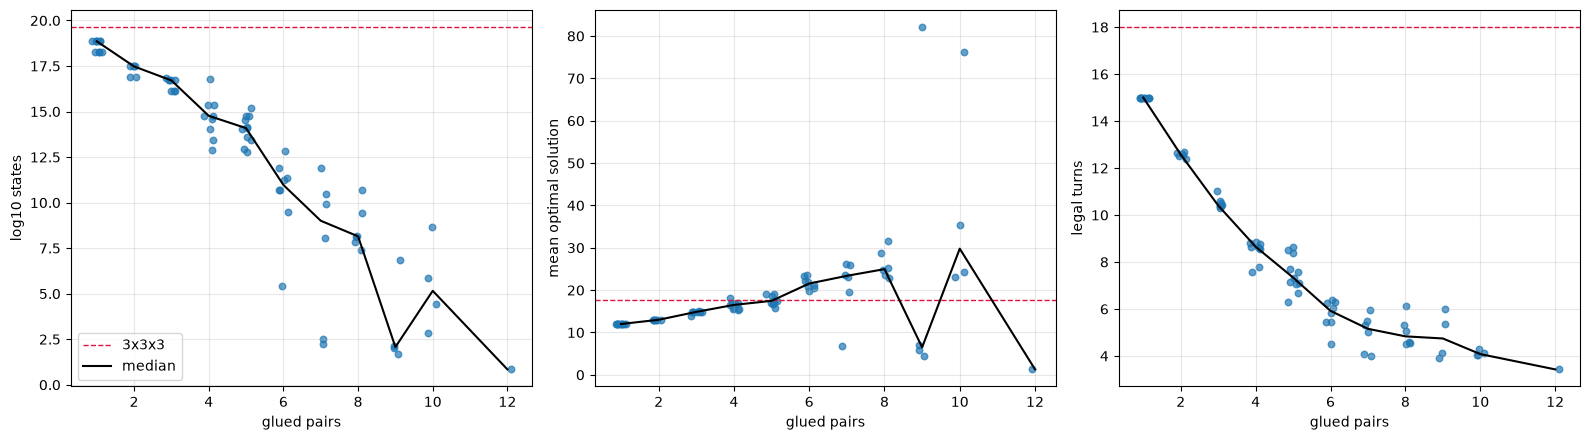

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, lab in zip(axes, ["log10_states", "mean_distance", "branching"],
                        ["log10 states", "mean optimal solution", "legal turns"]):
    ax.scatter(bp.bonds + rng.uniform(-.15, .15, len(bp)), bp[col], s=22, alpha=.7)
    ax.axhline(base[col], c="crimson", ls="--", lw=1, label="3x3x3")
    med = bp.groupby("bonds")[col].median()
    ax.plot(med.index, med.values, c="k", lw=1.5, label="median")
    ax.set_xlabel("glued pairs"); ax.set_ylabel(lab); ax.grid(alpha=.3)
axes[0].legend(); plt.tight_layout()

## Gallery: the extremes

The hardest puzzles by mean solution length, and the easiest non-trivial ones.

,spec,bonds,log10_states,gods_number,gods_lower,mean_distance,branching,edge3,corner3,edge_flip,corner_twist
id,,,,,,,,,,,
B053,ULB+UBR+UB | URF+DFR+FR | UFL+FL | BR+R | DF+F | DR+D | BL+L,9,6.851738,124.0,124,82.0996,5.3647,36.0,NaN,65.0,NaN
B018,UBR+UB | DBL+DB | FR+F | DLF+DR+DF+DL+D | UR+BR+R+B,10,4.432520,155.0,155,76.2072,4.0213,NaN,NaN,73.0,97.0
B004,ULB+UBR+UB | DLF+DF | URF+FR | DR+R | UF+UL+U+F | DL+D | BR+B,10,5.884927,55.0,55,35.3199,4.1250,35.0,NaN,15.0,31.0
B043,UFL+FL | DF+FR+F | DBL+DRB+DL+DB+D | UL+L,8,7.401301,NaN,38,31.7054,4.5268,21.0,NaN,33.0,23.0
B055,URF+UFL+UR+UF | UBR+UB | DRB+DB | DFR+DF+FR+F | DBL+DL+BL+L+B,12,0.845098,2.0,2,1.2857,3.4286,NaN,NaN,NaN,NaN
B072,UBR+UR | URF+UF | UFL+UL | UB+U | DRB+DB+FR+BR+R | FL+L,9,1.690196,9.0,9,4.3469,3.9184,NaN,NaN,NaN,NaN
B021,ULB+UB | DFR+FR | UFL+UF+FL | UR+R | DR+D | DBL+DB+BR+B,9,2.033424,11.0,11,5.9444,6.0000,NaN,NaN,NaN,NaN
B059,ULB+DBL+DL+BL | UBR+BR | DR+R | DRB+DB+B,7,2.245513,12.0,12,6.8977,4.0909,NaN,NaN,NaN,NaN


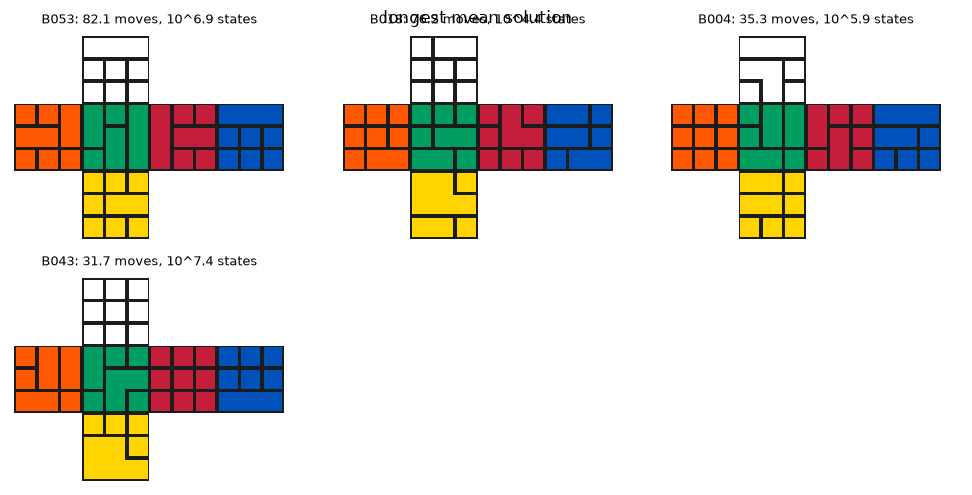

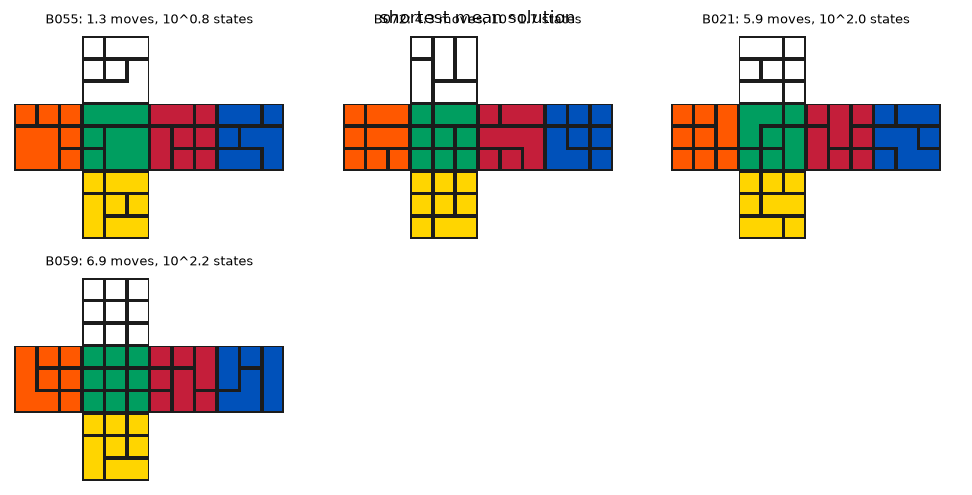

In [9]:
hard = bp.sort_values("mean_distance", ascending=False).head(4)
easy = bp.sort_values("mean_distance").head(4)
for name, sel in [("longest mean solution", hard), ("shortest mean solution", easy)]:
    rubik.plot_cubes([rubik.Cube(bandage=s) for s in sel.spec],
                     titles=[f"{i}: {'≥' if not r.mean_distance_exact else ''}{r.mean_distance:.1f} moves, 10^{r.log10_states:.1f} states"
                             for i, r in sel.iterrows()])
    plt.suptitle(name)
pd.concat([hard, easy])[["spec", "bonds", "log10_states", "gods_number", "gods_lower", "mean_distance", "branching"] + KINDS]

## Profile your own bandage

`rubik.difficulty` runs the same measurement on any bandage (a few seconds to a minute), and
`rubik.random_bandage(bonds, seed)` draws a random one.

```python
d = rubik.difficulty("URF+UF | DLF+DF | DRB+DB | DR+D | UL+FL+F+L")
d["states"], d["gods_number"], d["mean_distance"], d["edge3"]
```

## Caveats

* The 3x3x3's God's number (20) and mean distance (17.7) are published results (Rokicki et al.,
  2010): it is too deep for this sampler. Its state count and algorithm lengths were computed
  by the same code as every other puzzle.
* For large puzzles, `mean_distance` and `gods_lower` are lower bounds, so "longer than the 3x3x3"
  claims are safe, while "shorter" is only claimed when the value is exact.
* Algorithm lengths on large puzzles come from a time-limited search; hollow markers may not be optimal.
* "Difficulty" here is move count and puzzle size. Human difficulty also depends on how visible the
  blocked moves are and how hard the shape is to navigate, which these KPIs only approximate
  (branching captures part of it).